GLM Design 

In [2]:
import os
import os.path as op
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import nibabel as nib

from nilearn.glm.first_level import FirstLevelModel, make_first_level_design_matrix
from nilearn.glm import threshold_stats_img
from nilearn.image import mean_img
from nilearn.plotting import plot_design_matrix, plot_contrast_matrix, plot_stat_map

from utils import FSLeyesServer


In [3]:
data_root = "Data1"

fmri_path = op.join(
    data_root, "fMRI", "tfMRI_LANGUAGE_LR", "tfMRI_LANGUAGE_LR.nii.gz"
)
events_path = op.join(
    data_root, "fMRI", "tfMRI_LANGUAGE_LR",
    "tfMRI_LANGUAGE_LR_task_onsets.csv"
)

fmri_img = nib.load(fmri_path)
events = pd.read_csv(events_path)


In [4]:
events_glm = events[
    events["trial_type"].isin(["story", "math"])
].copy()
display(events_glm)


,onset,duration,trial_type
0,0.241,28.270,story
6,30.095,12.241,math
10,42.570,12.312,math
15,56.524,27.147,story
19,85.206,12.667,math
24,98.120,12.542,math
29,112.274,26.070,story
33,139.930,11.844,math
38,152.045,12.528,math
42,164.853,9.838,math


In [5]:
n_scans = fmri_img.shape[3]
tr = fmri_img.header.get_zooms()[3]

print("Number of scans:", n_scans)
print("TR:", tr)
print("Time units:", fmri_img.header.get_xyzt_units())

frame_times = np.arange(n_scans) * tr

Number of scans: 316
TR: 0.72
Time units: ('mm', 'sec')


In [6]:
motion_path = op.join("Data1", "derivatives", "preprocessed_data", "func", "bold_moco.par")
motion_params = pd.read_csv(motion_path, sep=r"\s+", header=None, names=["rot_x", "rot_y", "rot_z", "trans_x", "trans_y", "trans_z"])

print(motion_params.shape)
display(motion_params.head())

(316, 6)


,rot_x,rot_y,rot_z,trans_x,trans_y,trans_z
0,-0.000080,0.000388,-0.000901,0.020150,-0.043444,0.055774
1,0.000163,0.000492,-0.000059,0.030005,-0.038251,0.059965
2,-0.000031,0.000411,-0.001100,0.012959,-0.025233,0.051918
3,0.000297,-0.000309,-0.000091,-0.042305,-0.029215,0.039045
4,0.000089,-0.000224,-0.000001,-0.034639,-0.014459,0.047900


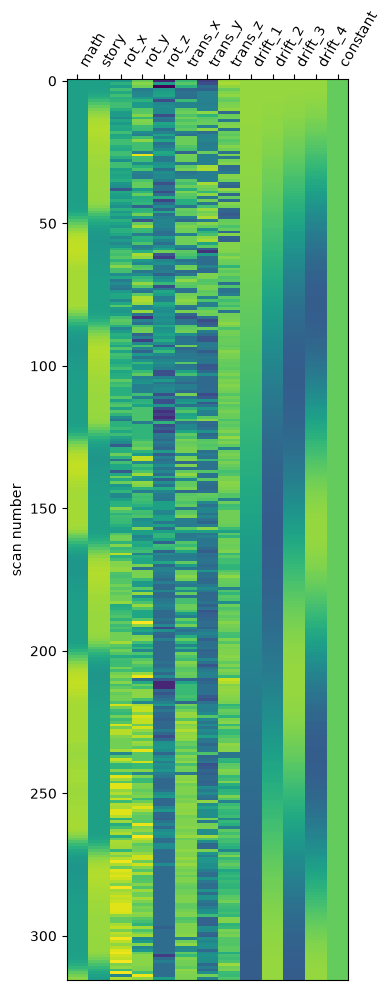

Regressors: ['math', 'story', 'rot_x', 'rot_y', 'rot_z', 'trans_x', 'trans_y', 'trans_z', 'drift_1', 'drift_2', 'drift_3', 'drift_4', 'constant']


In [7]:
design_matrix = make_first_level_design_matrix(
    frame_times=frame_times,
    events=events_glm,
    hrf_model="spm",
    drift_model="cosine",
    high_pass=0.01,
    add_regs=motion_params.to_numpy(),
    add_reg_names=motion_params.columns.tolist()
)

plot_design_matrix(design_matrix)
plt.show()
print("Regressors:", design_matrix.columns.tolist())

,math,story,rot_x,rot_y,rot_z,trans_x,trans_y,trans_z,drift_1,drift_2,drift_3,drift_4,constant
0.00,0.0,0.000000,-0.000080,0.000388,-0.000901,0.020150,-0.043444,0.055774,0.079555,0.079552,0.079547,0.079540,1.0
0.72,0.0,0.000011,0.000163,0.000492,-0.000059,0.030005,-0.038251,0.059965,0.079547,0.079520,0.079476,0.079414,1.0
1.44,0.0,0.001687,-0.000031,0.000411,-0.001100,0.012959,-0.025233,0.051918,0.079531,0.079457,0.079335,0.079163,1.0
2.16,0.0,0.016045,0.000297,-0.000309,-0.000091,-0.042305,-0.029215,0.039045,0.079508,0.079363,0.079123,0.078786,1.0
2.88,0.0,0.061108,0.000089,-0.000224,-0.000001,-0.034639,-0.014459,0.047900,0.079476,0.079237,0.078840,0.078285,1.0
3.60,0.0,0.147243,0.000297,-0.000207,0.000030,-0.034579,-0.014456,0.051957,0.079437,0.079080,0.078488,0.077660,1.0
4.32,0.0,0.270390,0.000156,-0.000059,-0.000164,-0.039121,-0.014469,0.041425,0.079390,0.078892,0.078065,0.076913,1.0
5.04,0.0,0.416043,0.000189,0.000146,-0.000646,0.019886,-0.014488,0.037544,0.079335,0.078673,0.077574,0.076043,1.0
5.76,0.0,0.566807,0.000297,-0.000059,-0.000208,-0.021276,-0.016605,0.045054,0.079272,0.078422,0.077013,0.075054,1.0
6.48,0.0,0.708149,0.000297,-0.000059,-0.000149,-0.021270,-0.014469,0.047002,0.079201,0.078141,0.076384,0.073946,1.0


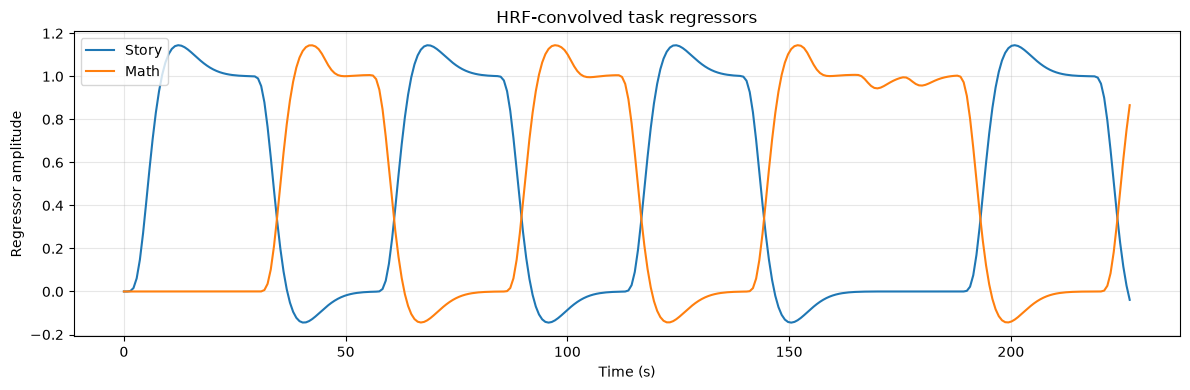

In [8]:
display(design_matrix.head(10))

plt.figure(figsize=(12, 4))
plt.plot(frame_times, design_matrix["story"], label="Story")
plt.plot(frame_times, design_matrix["math"], label="Math")
plt.xlabel("Time (s)")
plt.ylabel("Regressor amplitude")
plt.title("HRF-convolved task regressors")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("figures/3a_task_regressors-png", dpi=200)
plt.show()


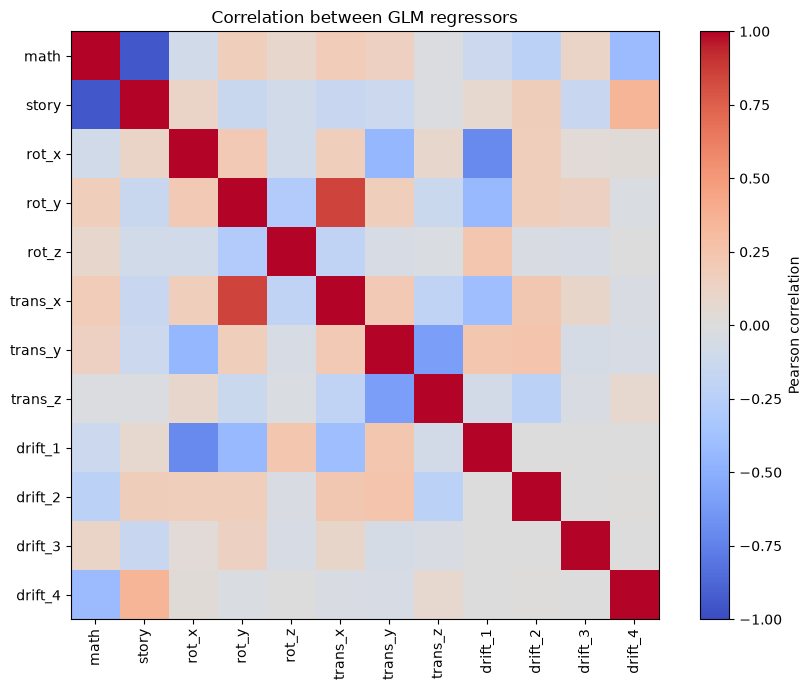

In [9]:
regressors = design_matrix.drop(columns=["constant"], errors="ignore")
corr_matrix = regressors.corr()

fig, ax = plt.subplots(figsize=(9, 7))
im = ax.imshow(corr_matrix, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr_matrix.columns)))
ax.set_yticks(range(len(corr_matrix.index)))
ax.set_xticklabels(corr_matrix.columns, rotation=90)
ax.set_yticklabels(corr_matrix.index)
plt.colorbar(im, ax=ax, label="Pearson correlation")
ax.set_title("Correlation between GLM regressors")
plt.tight_layout()
plt.savefig("figures/3b_correlation_matrix.png", dpi=200, bbox_inches="tight")
plt.show()


In [10]:
story_math_corr = corr_matrix.loc["story", "math"]
print("Correlation between Story and Math:", round(story_math_corr, 3))

print("Correlations with Story and Math:")
display(corr_matrix.loc[["story", "math"]].round(3))


Correlation between Story and Math: -0.941
Correlations with Story and Math:


,math,story,rot_x,rot_y,rot_z,trans_x,trans_y,trans_z,drift_1,drift_2,drift_3,drift_4
story,-0.941,1.000,0.113,-0.138,-0.091,-0.142,-0.118,-0.022,0.077,0.172,-0.143,0.346
math,1.000,-0.941,-0.088,0.172,0.090,0.184,0.142,-0.017,-0.125,-0.225,0.112,-0.415


In [11]:
preprocessed_path = op.join(data_root, "derivatives", "preprocessed_data", "func", "bold_moco_smoothed-6mm.nii.gz")
preprocessed_fmri_img = nib.load(preprocessed_path)

assert preprocessed_fmri_img.shape[3] == len(design_matrix)

In [12]:

fmri_glm = FirstLevelModel(
    t_r=float(tr),
    noise_model="ar1",
    standardize=False,
    hrf_model="spm",
    drift_model="cosine",
    high_pass=0.01
)

fmri_glm = fmri_glm.fit(
    preprocessed_fmri_img,
    design_matrices=design_matrix
)
print("GLM fitting completed")


GLM fitting completed


In [13]:
story_zmap = fmri_glm.compute_contrast("story", output_type="z_score")
math_zmap = fmri_glm.compute_contrast("math", output_type="z_score")
print("z-maps computed")


z-maps computed


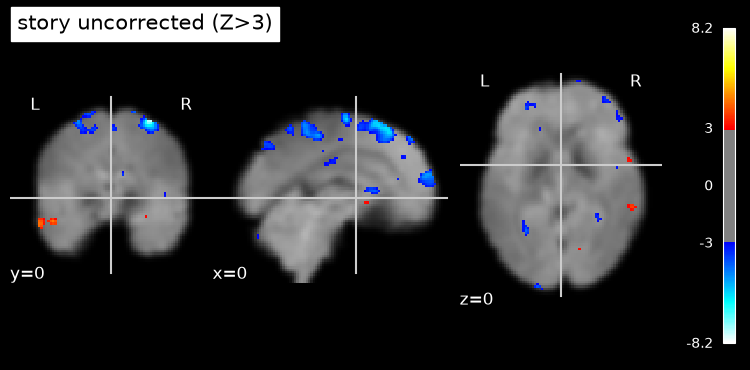

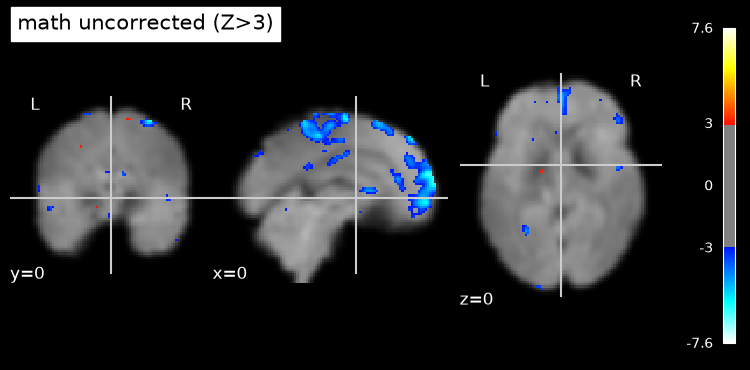

In [14]:
mean_fmri =  mean_img(preprocessed_fmri_img)

plot_stat_map(story_zmap, bg_img=mean_fmri, threshold=3.0, display_mode="ortho", cut_coords= (0,0,0),title="story uncorrected (Z>3)", colorbar=True)
plot_stat_map(math_zmap, bg_img=mean_fmri, threshold=3.0, display_mode="ortho", cut_coords= (0,0,0), title="math uncorrected (Z>3)", colorbar=True)
plt.show()



In [15]:
# save statistical maps for FSLeyes
output_dir = "results/GLM"
os.makedirs(output_dir, exist_ok=True)


nib.save(story_zmap, os.path.join(output_dir, "story_zmap.nii.gz"))
nib.save(math_zmap, os.path.join(output_dir, "math_zmap.nii.gz"))
nib.save(mean_fmri, "results/GLM/mean_fmri.nii.gz")

In [20]:
# Does not work properly so far, I want to overlay the z_maps in FSLeyes
fsleyesDisplay = FSLeyesServer()
fsleyesDisplay.show()

fsleyesDisplay.resetOverlays()
fsleyesDisplay.load(os.path.join("results/GLM/mean_fmri.nii.gz"))
fsleyesDisplay.load(os.path.join(output_dir, "story_zmap.nii.gz"))


In [21]:
fsleyesDisplay.resetOverlays()
fsleyesDisplay.load(os.path.join("results/GLM/mean_fmri.nii.gz"))
fsleyesDisplay.load(os.path.join(output_dir, "math_zmap.nii.gz"))

In [18]:
# Task 3d) Define contrast vectors
columns = design_matrix.columns
story_vs_math = np.zeros(len(columns))
story_vs_math[columns.get_loc("story")] = 1
story_vs_math[columns.get_loc("math")] = -1
math_vs_story = -story_vs_math

contrast_table = pd.DataFrame(
    [story_vs_math, math_vs_story],
    index=["Story > Math", "Math > Story"],
    columns=columns)

# compute contrast maps
story_vs_math_zmap = fmri_glm.compute_contrast(story_vs_math, output_type="z_score")
math_vs_story_zmap = fmri_glm.compute_contrast(math_vs_story, output_type="z_score")
print("Contrast maps computed")

Contrast maps computed


/opt/conda/lib/python3.13/site-packages/nilearn/glm/thresholding.py:297: UserWarning: The given float value must not exceed 8.245290293470134. But, you have given threshold=inf.
  stat_img = threshold_img(


Story: FDR threshold = inf
No positive voxels survive FDR correction.


/opt/conda/lib/python3.13/site-packages/nilearn/glm/thresholding.py:297: UserWarning: The given float value must not exceed 7.604418110595826. But, you have given threshold=inf.
  stat_img = threshold_img(


Math: FDR threshold = inf
No positive voxels survive FDR correction.
Story > Math: FDR threshold = 2.321


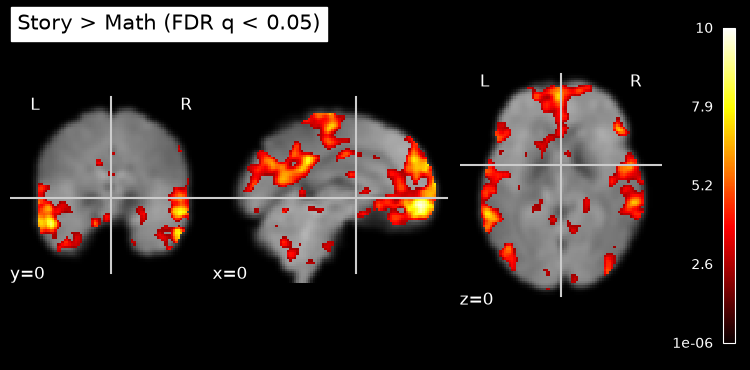

Math > Story: FDR threshold = 2.528


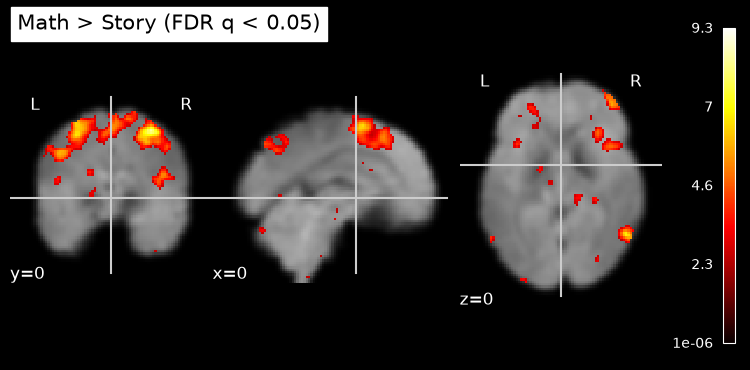

In [19]:
# FDR correction, but threshold infinite?
from nilearn.image import math_img

maps = {
    "Story": story_zmap,
    "Math": math_zmap,
    "Story > Math": story_vs_math_zmap,
    "Math > Story": math_vs_story_zmap
}

corrected_maps = {}

for title, zmap in maps.items():

    # Voxel-wise FDR correction (q = 0.05)
    corrected_map, threshold = threshold_stats_img(
        zmap,
        mask_img=fmri_glm.masker_.mask_img_,
        alpha=0.05,
        height_control="fdr",
        two_sided=False
    )

    corrected_maps[title] = corrected_map

    print(f"{title}: FDR threshold = {threshold:.3f}")

    if np.isfinite(threshold):

        # Show positive effects only
        positive_map = math_img(
            "np.maximum(img, 0)",
            img=corrected_map
        )

        plot_stat_map(
            positive_map,
            bg_img=mean_fmri,
            display_mode="ortho",
            cut_coords=(0, 0, 0),
            cmap="hot",
            title=f"{title} (FDR q < 0.05)",
            colorbar=True
        )
        plt.show()

    else:
        print("No positive voxels survive FDR correction.")